# Codex diagnostic: NOAA versus CMIP6 equivalent-depth distributions

**Agent-authored exploratory analysis.** This notebook is separate from the project's established analysis notebooks. It compares one NOAA record with the 59 completed CMIP6 simulations (34 Historical, 25 AMIP), each with one available member, during 1990–2010. No figure files are written; figures appear only as notebook outputs.

**Question.** How do fitted event depths, energy on detected event footprints, and spectral power mapped to apparent depth differ between NOAA and individual CMIP6 simulations? The three measures answer distinct questions and should not be treated as interchangeable.


## Inputs and choices

- Inputs are the audited compressed tables from `scripts/codex_cmip_heff/` and the matching NOAA calculation. All access is through `data/`.
- All records use the 1.5-standard-deviation event detector, raw constant-amplitude sinusoid fitting on active event pixels, the same rectangular wave boxes, and each model's native calendar. The primary plots use the existing `keep_for_histogram` fit-quality screen. The summary table also reports the relaxed finite-depth selection.
- **Event count distributions** normalize each simulation's selected events separately; a model with more events therefore does not dominate the ensemble curve. The 50 log bins span 0.5–10,000 m.
- **Event energy** is filtered OLR squared on active component pixels, grouped by each event's fitted depth. This includes background energy on those pixels. **Fitted energy** uses the in-sample sinusoid R² on the same pixels. Their denominator is the sum of squares of both preprocessed, projected OLR components, before wave filtering.
- **Spectral power** assigns an apparent resting-background depth to each Fourier cell in the actual wave box. Its denominator is total projected spectral power. The smoothed Gaussian background is estimated separately from each simulation, and is included only in the integrated metric table here.
- Each model/experiment/member is one observation in ensemble medians and interquartile ranges; these are **between-simulation spreads**, not confidence intervals. A single NOAA record and one available member per model do not isolate forced differences from internal variability. Equivalent depths also retain the zero-background-wind dispersion assumption.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.paths import DATA_DIR

INPUT = DATA_DIR / "wave_significance/codex_cmip_heff_comparison"
WAVES = ("Kelvin", "MRG", "n0EIG", "n1ERW", "n1WIG")
EXPERIMENTS = ("historical", "amip")
LINEAR_EDGES_M = np.arange(1.0, 201.0)
LOG_EDGES_M = np.logspace(np.log10(0.5), np.log10(10_000), 51)
COUNT_BINS = [f"count_{left:03d}m" for left in range(1, 200)]
LOG_BINS = [f"log_count_{index:02d}" for index in range(50)]
SUPPORT_BINS = [f"support_{left:03d}m" for left in range(1, 200)]
FITTED_BINS = [f"fitted_{left:03d}m" for left in range(1, 200)]
POWER_BINS = [f"power_{left:03d}m" for left in range(1, 200)]

def read_table(name):
    path = INPUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Run and audit scripts/codex_cmip_heff first: {path}")
    return pd.read_csv(path)

model_counts = read_table("all_model_event_counts.csv.gz")
model_energy = read_table("all_model_event_energy.csv.gz")
model_spectral = read_table("all_model_spectral_power.csv.gz")
noaa_counts = read_table("noaa_event_counts.csv.gz")
noaa_energy = read_table("noaa_event_energy.csv.gz")
noaa_spectral = read_table("noaa_spectral_power.csv.gz")

for label, frame, expected in (
    ("model counts", model_counts, 590), ("model energy", model_energy, 590),
    ("model spectral", model_spectral, 590), ("NOAA counts", noaa_counts, 10),
    ("NOAA energy", noaa_energy, 10), ("NOAA spectral", noaa_spectral, 10),
):
    if len(frame) != expected or set(frame.wave_type) != set(WAVES):
        raise RuntimeError(f"Incomplete {label}: {len(frame)} rows")
if not (set(COUNT_BINS + LOG_BINS).issubset(model_counts)
        and set(SUPPORT_BINS + FITTED_BINS).issubset(model_energy)
        and set(POWER_BINS).issubset(model_spectral)):
    raise RuntimeError("Missing expected depth bins")
print("Loaded 59 model simulations and one NOAA record; 1,000 NOAA nulls are in the separate NOAA notebook.")


Matplotlib is building the font cache; this may take a moment.


Loaded 59 model simulations and one NOAA record; 1,000 NOAA nulls are in the separate NOAA notebook.


## Integrated 12–50 m diagnostics

The table reports each simulation separately, plus NOAA. Event-count percentage is the share of **selected events** in this range. Event and spectral percentages instead use **total projected OLR energy/power** as the denominator. The spectral observed/background ratio uses absolute power in the range, with each source's own smooth background; it is not an event-level significance test. The 12–50 m range is motivated by Wheeler–Kiladis and is displayed as a descriptive summary, not a multiplicity-adjusted test.


In [2]:
KEY = ["model", "experiment", "member", "wave_type"]
SELECTION_KEY = KEY + ["selection"]

def integrated_metrics(counts, energy, spectral):
    count = counts[SELECTION_KEY + ["record_days", "selected_events"]].copy()
    count["event_share_12_to_50_pct"] = (
        100 * counts[[f"count_{left:03d}m" for left in range(12, 50)]].sum(axis=1)
        / counts.selected_events
    )
    count["events_per_1000_days"] = 1000 * counts.selected_events / counts.record_days

    event = energy[SELECTION_KEY].copy()
    for metric in ("support", "fitted"):
        bins = [f"{metric}_{left:03d}m" for left in range(12, 50)]
        event[f"{metric}_12_to_50_pct"] = 100 * energy[bins].sum(axis=1) / energy.denominator_energy
        event[f"{metric}_all_depths_pct"] = (
            100 * energy[f"selected_{metric}_energy"] / energy.denominator_energy
        )

    spec = spectral[KEY + ["source", "denominator_power", "twelve_to_50_m_power"]].copy()
    spec["spectral_12_to_50_pct"] = 100 * spec.twelve_to_50_m_power / spec.denominator_power
    observed = spec.loc[spec.source.eq("observed"), KEY + ["spectral_12_to_50_pct", "twelve_to_50_m_power"]]
    background = spec.loc[spec.source.eq("background"), KEY + ["twelve_to_50_m_power"]]
    spec_pair = observed.merge(background, on=KEY, validate="one_to_one", suffixes=("_observed", "_background"))
    spec_pair["spectral_12_to_50_observed_to_background"] = (
        spec_pair.twelve_to_50_m_power_observed / spec_pair.twelve_to_50_m_power_background
    )
    return (count.merge(event, on=SELECTION_KEY, validate="one_to_one")
            .merge(spec_pair[KEY + ["spectral_12_to_50_pct",
                                     "spectral_12_to_50_observed_to_background"]],
                   on=KEY, validate="many_to_one"))

metrics = pd.concat((integrated_metrics(model_counts, model_energy, model_spectral),
                     integrated_metrics(noaa_counts, noaa_energy, noaa_spectral)), ignore_index=True)
assert len(metrics) == 600 and metrics[KEY + ["selection"]].duplicated().sum() == 0
primary = metrics.loc[metrics.selection.eq("screened")].copy()
display(primary.loc[primary.model.eq("NOAA_OLR"),
                    ["wave_type", "selected_events", "event_share_12_to_50_pct",
                     "support_12_to_50_pct", "fitted_12_to_50_pct",
                     "spectral_12_to_50_pct", "spectral_12_to_50_observed_to_background"]].round(3))
display(primary.loc[primary.model.ne("NOAA_OLR")].groupby(["experiment", "wave_type"])[
    ["event_share_12_to_50_pct", "support_12_to_50_pct",
     "fitted_12_to_50_pct", "spectral_12_to_50_pct",
     "spectral_12_to_50_observed_to_background"]].median().round(3))


,wave_type,selected_events,event_share_12_to_50_pct,support_12_to_50_pct,fitted_12_to_50_pct,spectral_12_to_50_pct,spectral_12_to_50_observed_to_background
590,Kelvin,767,70.013,3.180,1.967,4.258,1.576
592,MRG,806,43.548,0.721,0.506,0.960,1.144
594,n0EIG,1409,23.279,0.441,0.271,0.971,1.390
596,n1ERW,215,75.349,3.498,2.053,4.264,1.440
598,n1WIG,2036,9.283,0.080,0.050,0.294,1.014


event_share_12_to_50_pct  support_12_to_50_pct  \
experiment wave_type                                                   
amip       Kelvin                       48.230                 1.441   
           MRG                          35.935                 0.493   
           n0EIG                         4.041                 0.025   
           n1ERW                        66.190                 3.152   
           n1WIG                         2.711                 0.006   
historical Kelvin                       45.567                 1.559   
           MRG                          36.283                 0.560   
           n0EIG                         4.419                 0.031   
           n1ERW                        67.344                 3.226   
           n1WIG                         2.580                 0.006   

                      fitted_12_to_50_pct  spectral_12_to_50_pct  \
experiment wave_type                                               
amip       Kelvin                   0.930                  2.283   
           MRG                      0.353                  0.692   
           n0EIG                    0.018                  0.294   
           n1ERW                    1.990                  4.664   
           n1WIG                    0.005                  0.110   
historical Kelvin                   0.991                  2.485   
           MRG                      0.409                  0.696   
           n0EIG                    0.021                  0.345   
           n1ERW                    2.096                  4.547   
           n1WIG                    0.004                  0.123   

                      spectral_12_to_50_observed_to_background  
experiment wave_type                                            
amip       Kelvin                                        1.215  
           MRG                                           0.997  
           n0EIG                                         0.965  
           n1ERW                                         1.381  
           n1WIG                                         0.867  
historical Kelvin                                        1.291  
           MRG                                           0.982  
           n0EIG                                         1.012  
           n1ERW                                         1.345  
           n1WIG                                         0.877

The next table keeps the **individual** simulations visible. `support_12_to_50_pct` is the event-footprint energy share; sort or filter `primary` to inspect the other metrics or the relaxed selection. Historical and AMIP should not be pooled as if their records were independent members of one experiment.


In [3]:
model_table = primary.loc[primary.model.ne("NOAA_OLR")].pivot(
    index=["model", "experiment", "member"], columns="wave_type",
    values="support_12_to_50_pct")
display(model_table.reindex(columns=WAVES).round(3))


wave_type                            Kelvin    MRG  n0EIG  n1ERW  n1WIG
model           experiment member                                      
ACCESS-CM2      amip       r1i1p1f1   1.825  0.614  0.028  2.896  0.010
                historical r1i1p1f1   2.761  0.582  0.029  2.622  0.015
ACCESS-ESM1-5   amip       r1i1p1f1   1.116  0.412  0.006  3.306  0.003
                historical r1i1p1f1   1.386  0.493  0.006  2.773  0.001
AWI-ESM-1-1-LR  historical r1i1p1f1   0.841  0.460  0.010  4.165  0.002
AWI-ESM-1-REcoM historical r1i1p1f1   0.891  0.435  0.007  3.942  0.001
BCC-CSM2-MR     amip       r1i1p1f1   3.628  0.838  0.115  2.806  0.125
                historical r2i1p1f1   4.559  0.782  0.142  3.626  0.152
BCC-ESM1        historical r1i1p1f1   4.701  0.716  0.069  3.182  0.028
CESM2           amip       r1i1p1f1   2.013  0.972  0.079  3.424  0.011
                historical r1i1p1f1   2.152  0.748  0.086  3.163  0.012
CESM2-FV2       amip       r1i1p1f1   1.706  1.073  0.120  4.231  0.029
                historical r1i1p1f1   1.885  0.892  0.119  3.269  0.019
CESM2-WACCM     amip       r1i1p1f1   2.170  0.994  0.067  3.402  0.015
                historical r1i1p1f1   2.741  0.809  0.084  3.723  0.010
CESM2-WACCM-FV2 amip       r1i1p1f1   1.812  1.058  0.135  3.032  0.024
                historical r1i1p1f1   2.227  0.948  0.145  2.954  0.032
CMCC-CM2-SR5    historical r1i1p1f1   3.093  1.221  0.059  3.020  0.005
CNRM-CM6-1      amip       r1i1p1f2   0.816  0.449  0.024  2.887  0.005
                historical r1i1p1f2   0.584  0.511  0.040  3.403  0.004
CNRM-CM6-1-HR   amip       r1i1p1f2   1.226  0.836  0.041  3.457  0.003
                historical r1i1p1f2   1.181  0.555  0.058  3.959  0.004
CNRM-ESM2-1     amip       r1i1p1f2   0.673  0.473  0.027  3.017  0.004
                historical r1i1p1f2   0.716  0.565  0.054  3.819  0.006
CanESM5         amip       r1i1p1f1   1.076  0.347  0.009  2.419  0.008
                historical r1i1p1f1   1.180  0.487  0.011  3.634  0.008
FGOALS-g3       historical r1i1p1f1   1.613  0.396  0.034  2.538  0.009
GFDL-CM4        amip       r1i1p1f1   0.937  0.637  0.008  2.885  0.002
                historical r1i1p1f1   1.221  0.565  0.008  2.873  0.003
GISS-E2-1-G     amip       r1i1p1f1   0.919  0.491  0.006  2.383  0.002
                historical r1i1p1f1   1.337  0.412  0.013  3.131  0.002
HadGEM3-GC31-LL amip       r1i1p1f3   1.644  0.568  0.037  3.152  0.006
                historical r1i1p1f3   2.799  0.622  0.026  3.097  0.008
HadGEM3-GC31-MM amip       r2i1p1f3   1.838  0.551  0.034  3.035  0.009
                historical r1i1p1f3   2.857  0.588  0.041  2.658  0.011
ICON-ESM-LR     amip       r1i1p1f1   0.870  0.468  0.009  2.213  0.001
                historical r1i1p1f1   0.654  0.451  0.005  3.720  0.001
INM-CM4-8       amip       r1i1p1f1   0.573  0.283  0.002  3.534  0.002
                historical r1i1p1f1   0.591  0.295  0.001  4.095  0.001
INM-CM5-0       amip       r1i1p1f1   0.535  0.258  0.002  3.212  0.001
                historical r1i1p1f1   0.649  0.348  0.002  3.596  0.001
IPSL-CM6A-LR    amip       r1i1p1f1   1.343  0.259  0.017  3.982  0.006
                historical r1i1p1f1   1.685  0.314  0.017  4.647  0.006
KACE-1-0-G      historical r1i1p1f1   2.860  0.626  0.034  3.109  0.007
MIROC6          amip       r1i1p1f1   2.066  0.726  0.025  3.123  0.004
                historical r1i1p1f1   2.599  0.543  0.023  3.126  0.005
MPI-ESM-1-2-HAM amip       r1i1p1f1   1.631  0.233  0.031  1.709  0.015
                historical r1i1p1f1   0.962  0.256  0.037  2.783  0.011
MPI-ESM1-2-HR   amip       r1i1p1f1   1.441  0.459  0.010  3.640  0.003
                historical r1i1p1f1   1.505  0.396  0.009  3.953  0.003
MPI-ESM1-2-LR   amip       r1i1p1f1   1.378  0.298  0.010  3.601  0.006
                historical r1i1p1f1   1.168  0.403  0.012  5.637  0.002
MRI-ESM2-0      amip       r1i1p1f1   1.664  0.493  0.009  3.661  0.002
                historical r1i1p1f1   1.

## Fitted event-depth distributions

Each standalone panel compares NOAA with Historical and AMIP **model medians** and interquartile ranges. A model contributes one normalized curve, regardless of its event count. These log-bin curves include the high-depth tails omitted from the 1–200 m energy panels. The primary fit-quality screen is shown; the `metrics` table also contains relaxed-selection results.


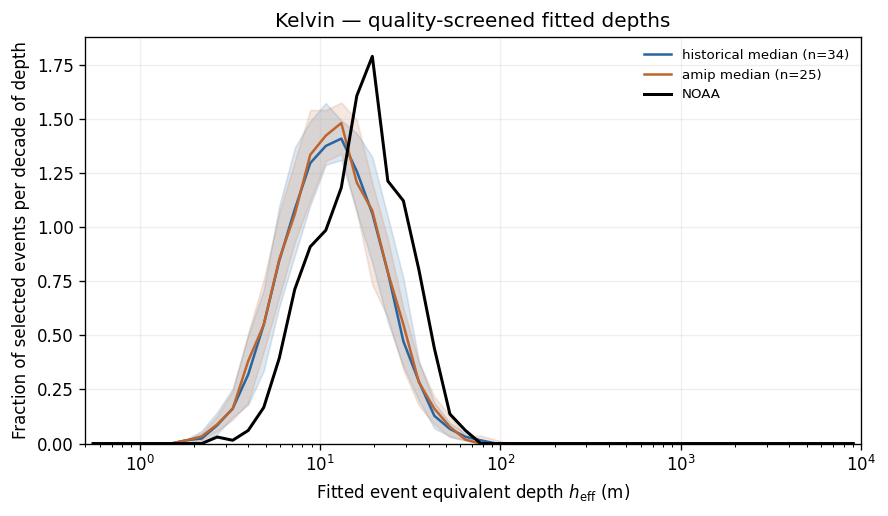

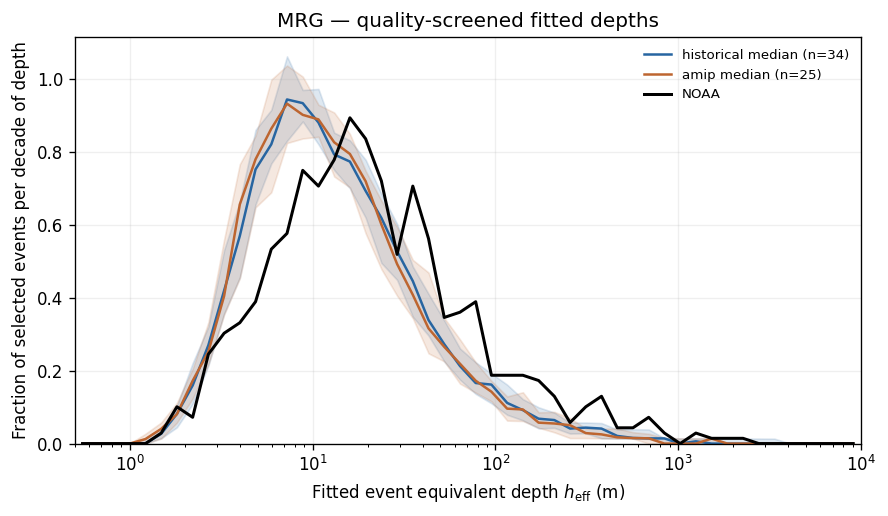

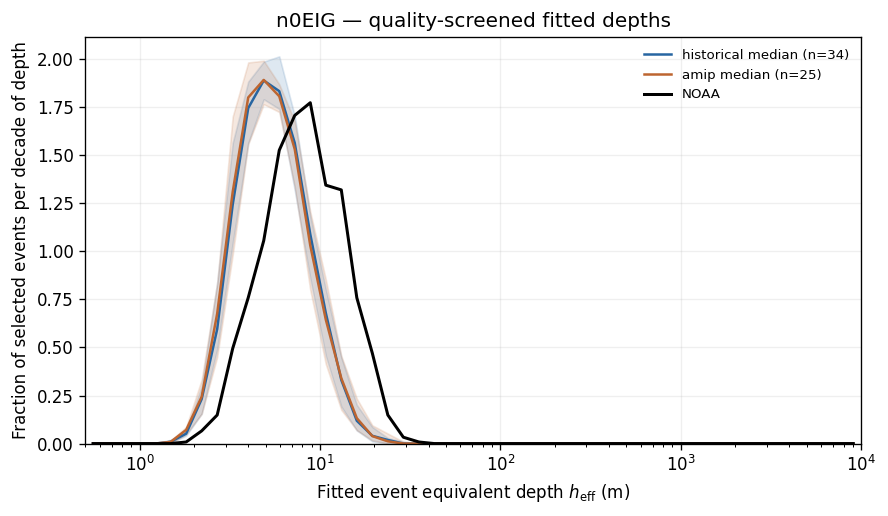

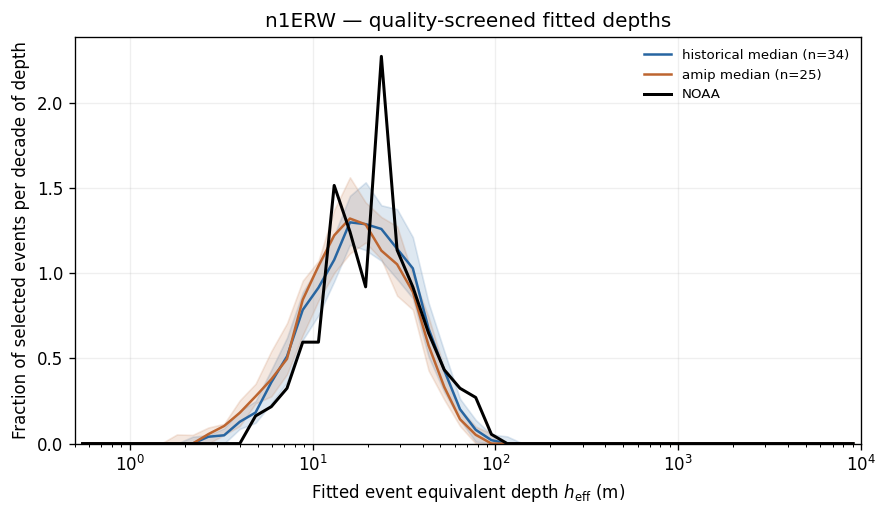

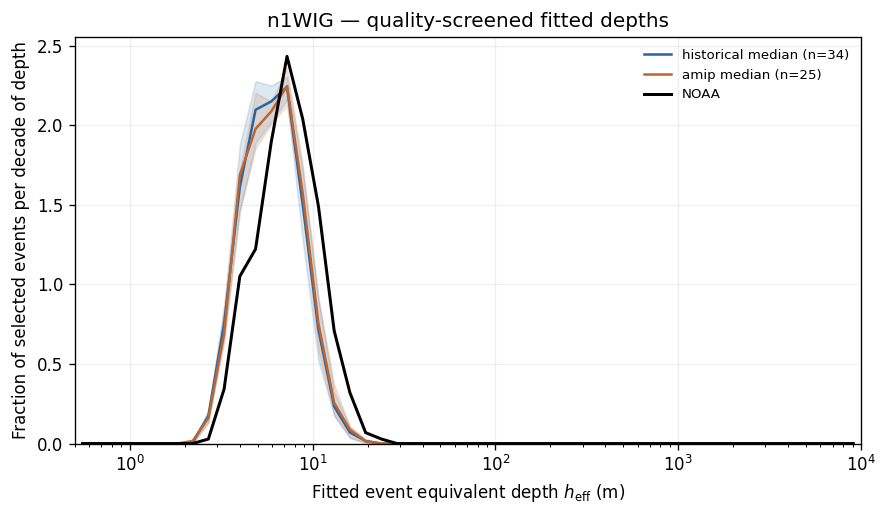

In [4]:
log_widths = np.diff(np.log10(LOG_EDGES_M))
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
    for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
        rows = model_counts.loc[(model_counts.wave_type == wave)
                                & (model_counts.selection == "screened")
                                & (model_counts.experiment == experiment)]
        density = rows[LOG_BINS].to_numpy() / rows.selected_events.to_numpy()[:, None] / log_widths
        low, median, high = np.quantile(density, [0.25, 0.5, 0.75], axis=0)
        centers = np.sqrt(LOG_EDGES_M[:-1] * LOG_EDGES_M[1:])
        ax.plot(centers, median, color=color, label=f"{experiment} median (n={len(rows)})")
        ax.fill_between(centers, low, high, color=color, alpha=0.15)
    row = noaa_counts.loc[(noaa_counts.wave_type == wave)
                          & (noaa_counts.selection == "screened")].iloc[0]
    noaa_density = row[LOG_BINS].to_numpy(dtype=float) / row.selected_events / log_widths
    ax.plot(centers, noaa_density, color="black", linewidth=1.8, label="NOAA")
    ax.set(xscale="log", xlim=(0.5, 10_000), ylim=(0, None),
           xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Fraction of selected events per decade of depth",
           title=f"{wave} — quality-screened fitted depths")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Linear detail: fitted event depths from 1 to 100 m

Each panel uses 1 m bins (1–2, 2–3, …, 99–100 m). The y-axis is the **percentage of all selected events in that record** per bin; events outside 1–100 m remain in the denominator. Historical and AMIP lines are medians of individually normalized model records, with between-simulation interquartile bands. NOAA is one record. Both the standard fit-quality screen and the relaxed finite-depth selection are shown, so changes in the screen are visible without changing the event detector.

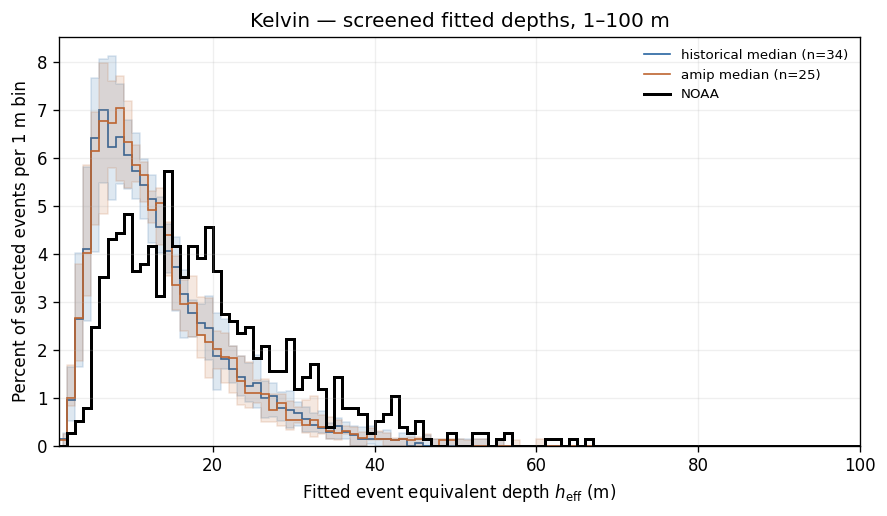

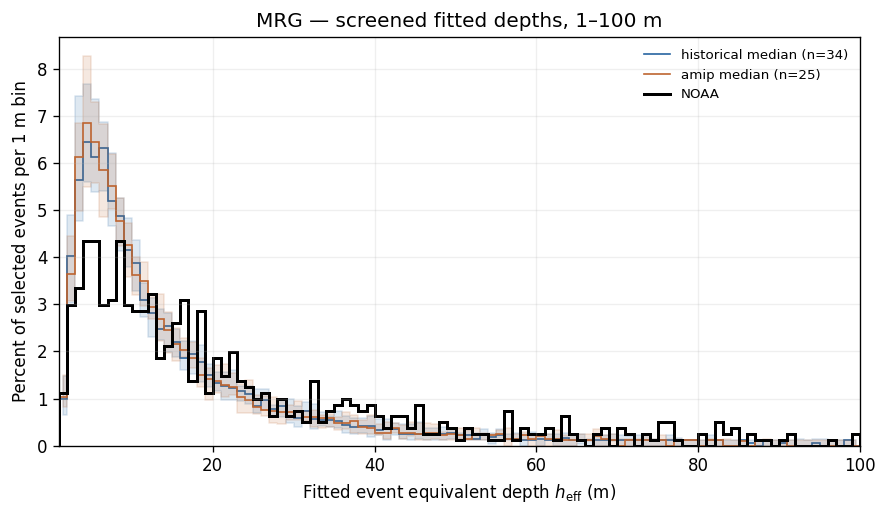

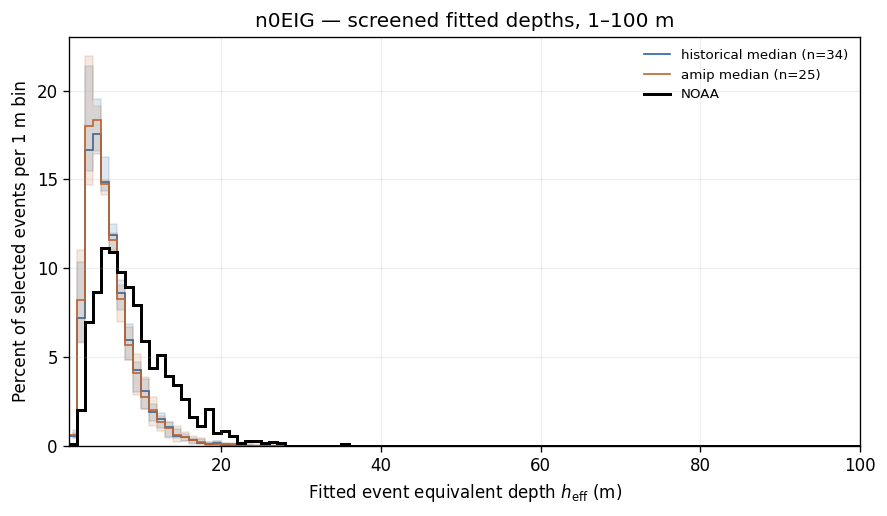

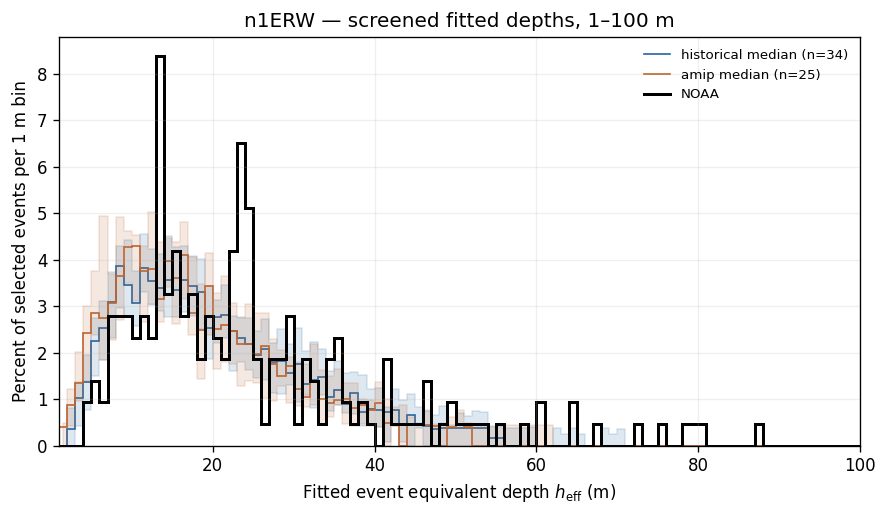

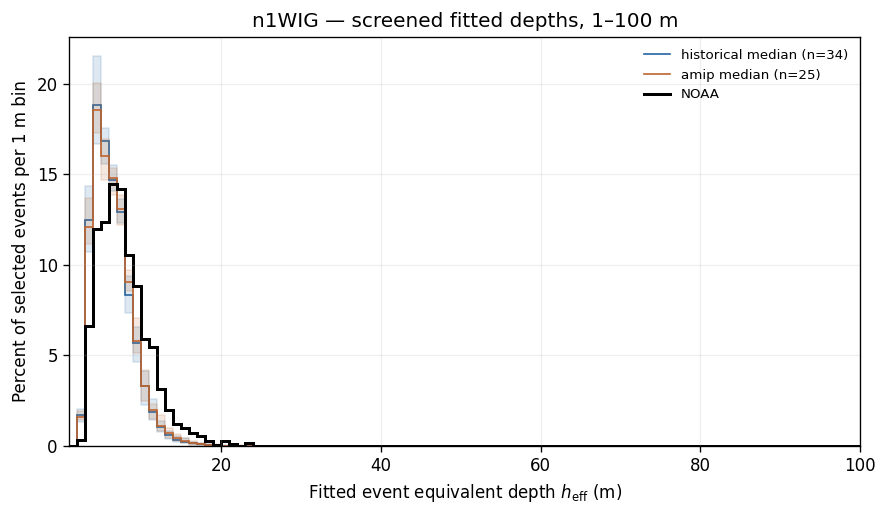

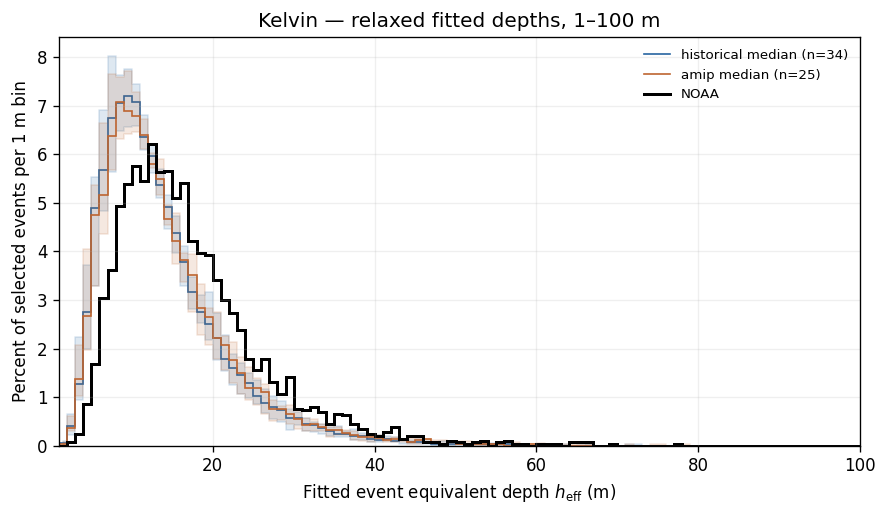

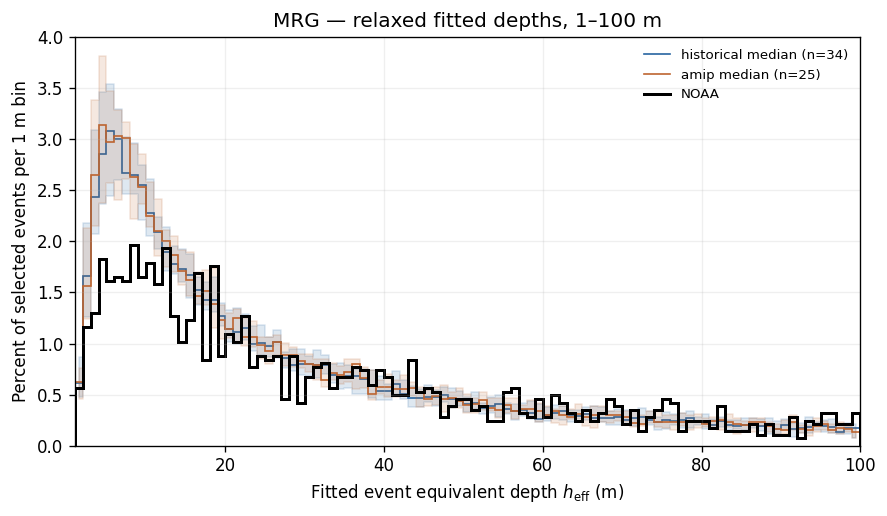

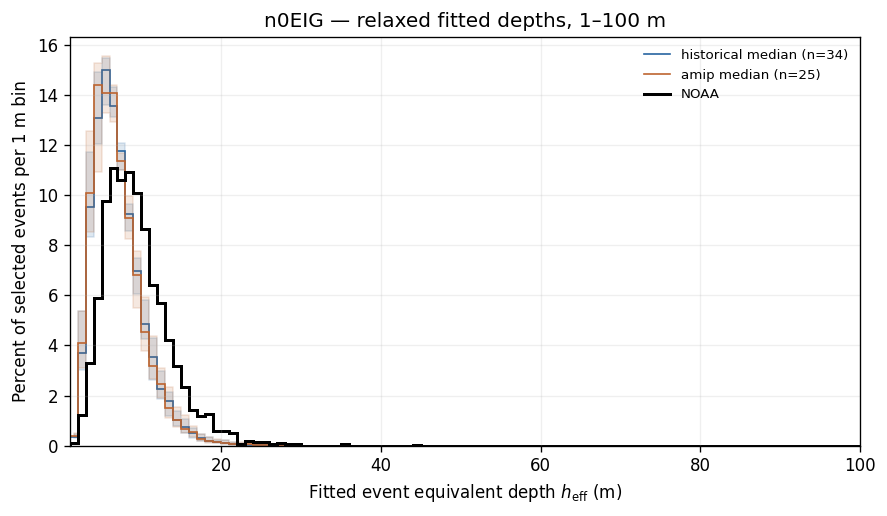

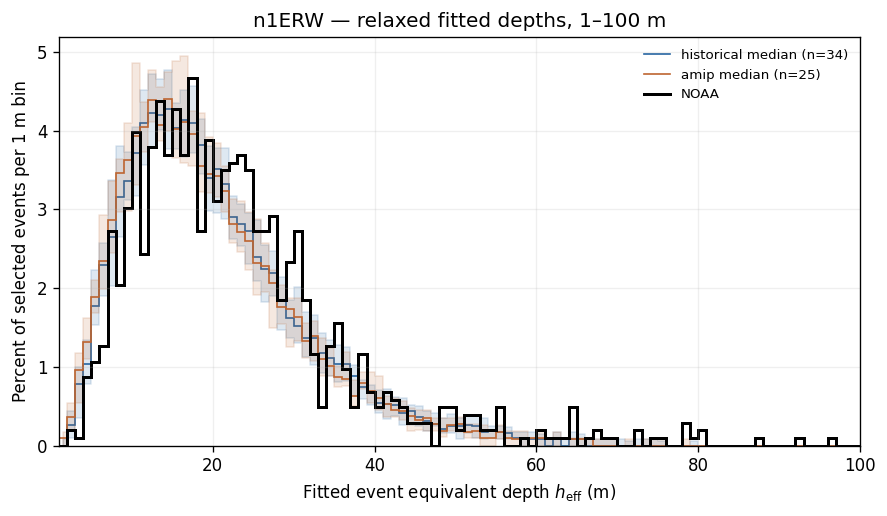

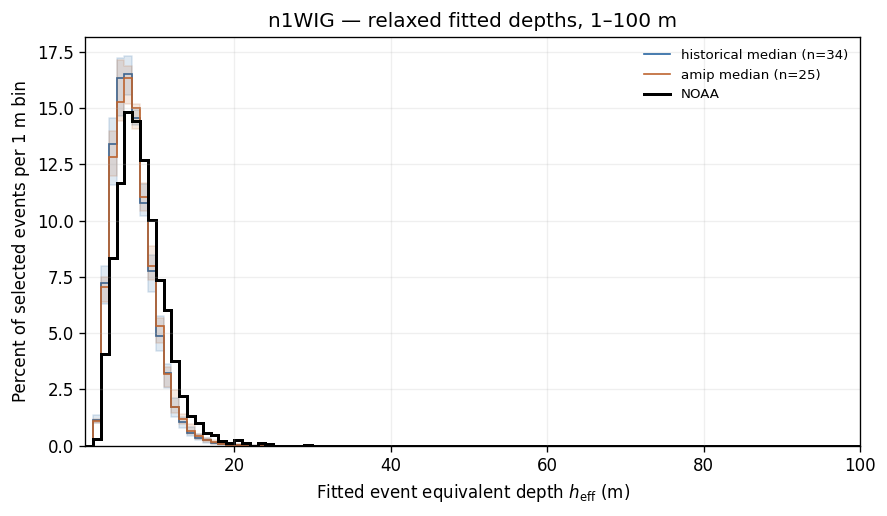

In [5]:
LINEAR_DETAIL_EDGES_M = np.arange(1.0, 101.0)
LINEAR_DETAIL_BINS = [f"count_{left:03d}m" for left in range(1, 100)]
LINEAR_DETAIL_CENTERS_M = (LINEAR_DETAIL_EDGES_M[:-1] + LINEAR_DETAIL_EDGES_M[1:]) / 2

for selection in ("screened", "relaxed"):
    for wave in WAVES:
        fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
        for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
            rows = model_counts.loc[(model_counts.wave_type == wave)
                                    & (model_counts.selection == selection)
                                    & (model_counts.experiment == experiment)]
            percent = (100 * rows[LINEAR_DETAIL_BINS].to_numpy()
                       / rows.selected_events.to_numpy()[:, None])
            low, median, high = np.quantile(percent, [0.25, 0.5, 0.75], axis=0)
            ax.stairs(median, LINEAR_DETAIL_EDGES_M, color=color,
                      label=f"{experiment} median (n={len(rows)})")
            ax.fill_between(LINEAR_DETAIL_CENTERS_M, low, high,
                            step="mid", color=color, alpha=0.15)
        row = noaa_counts.loc[(noaa_counts.wave_type == wave)
                              & (noaa_counts.selection == selection)].iloc[0]
        noaa_percent = (100 * row[LINEAR_DETAIL_BINS].to_numpy(dtype=float)
                        / row.selected_events)
        ax.stairs(noaa_percent, LINEAR_DETAIL_EDGES_M, color="black",
                  linewidth=1.8, label="NOAA")
        ax.set(xlim=(1, 100), ylim=(0, None),
               xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
               ylabel="Percent of selected events per 1 m bin",
               title=f"{wave} — {selection} fitted depths, 1–100 m")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=8)
        fig.tight_layout()
        display(fig)
        plt.close(fig)


## Individual-model spread in fitted depths, 1–100 m

Each faint line is one available model/experiment record (one member per simulation). The bold Historical and AMIP curves are arithmetic means of the individually normalized model histograms; each simulation has equal weight. NOAA is black. The 1 m bins and percentage denominator match the linear median panels above: events outside 1–100 m remain in the denominator. Both screened and relaxed selections are shown. These lines display between-simulation spread, not uncertainty in the ensemble mean.


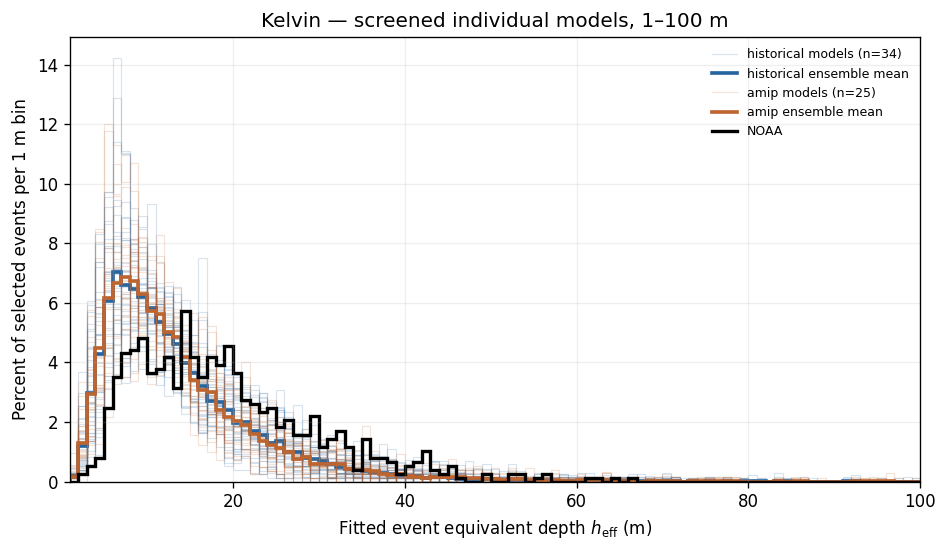

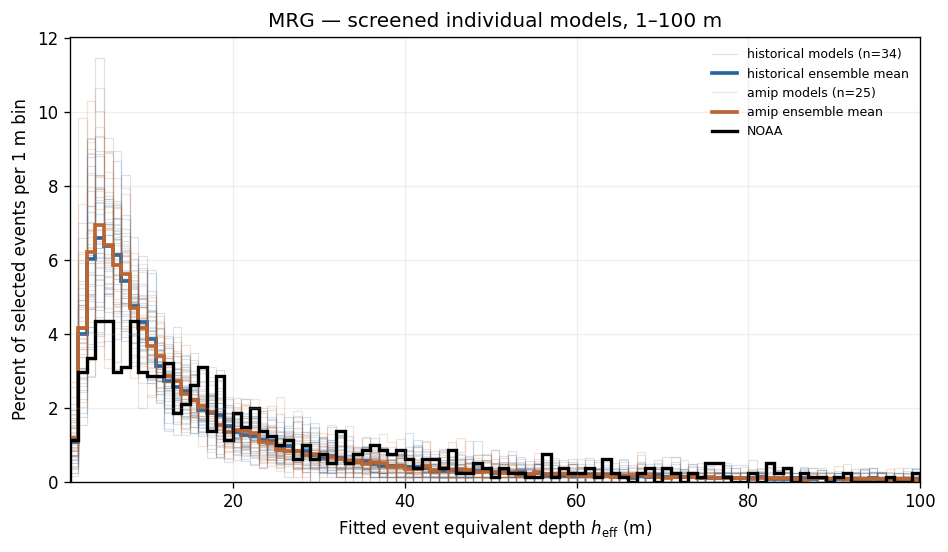

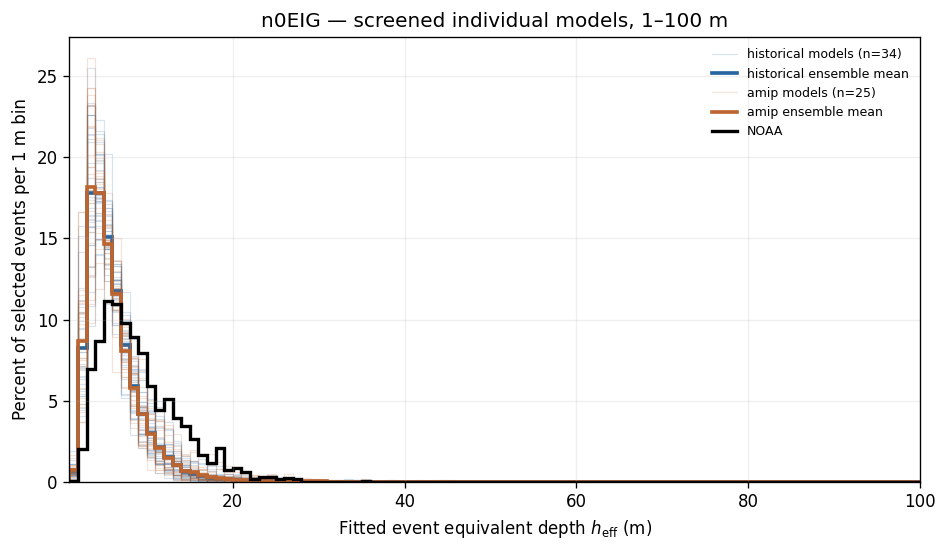

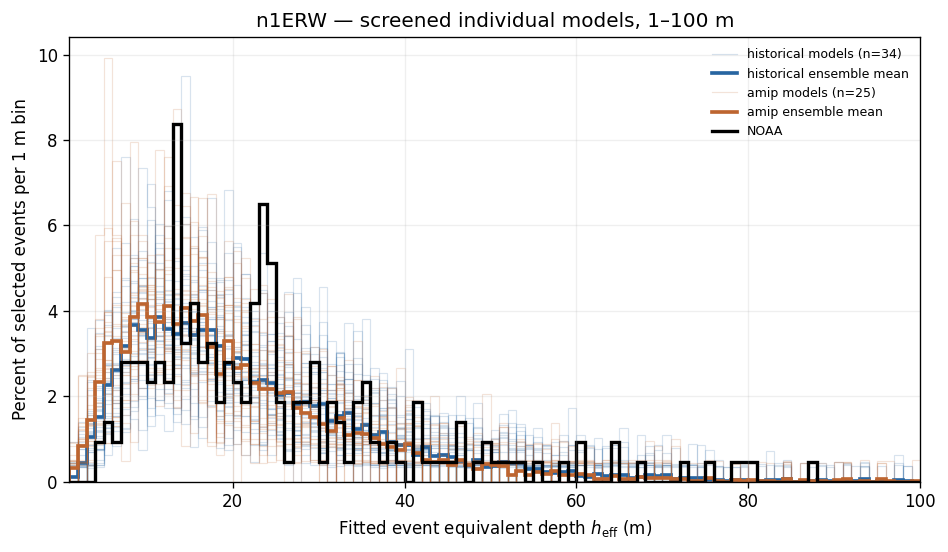

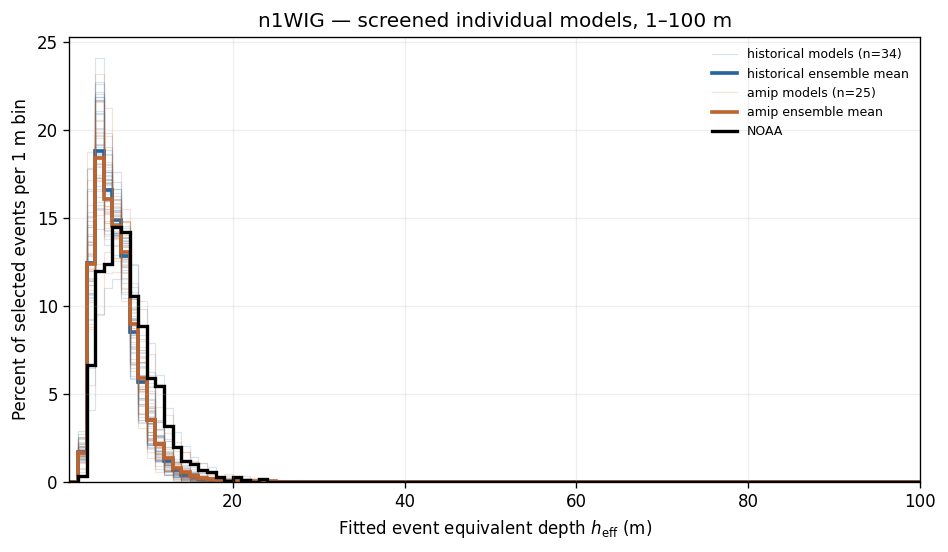

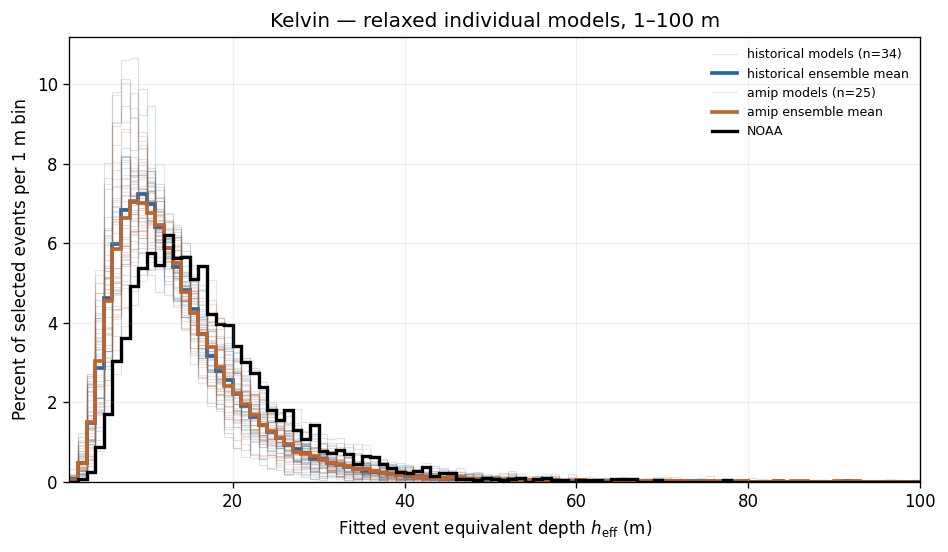

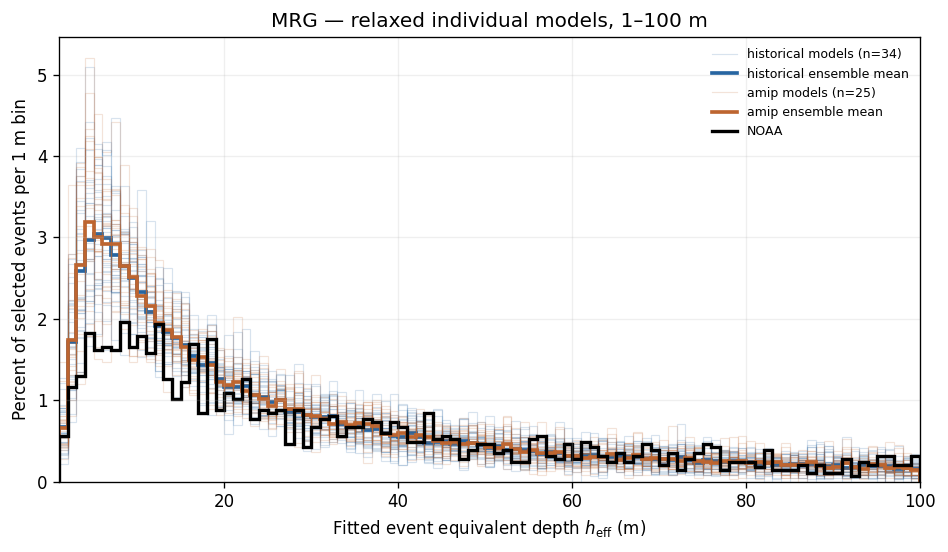

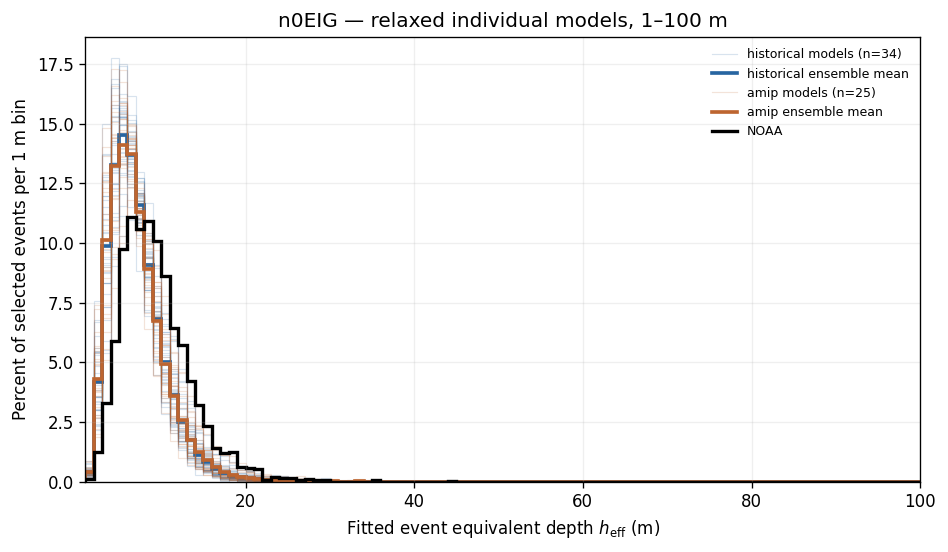

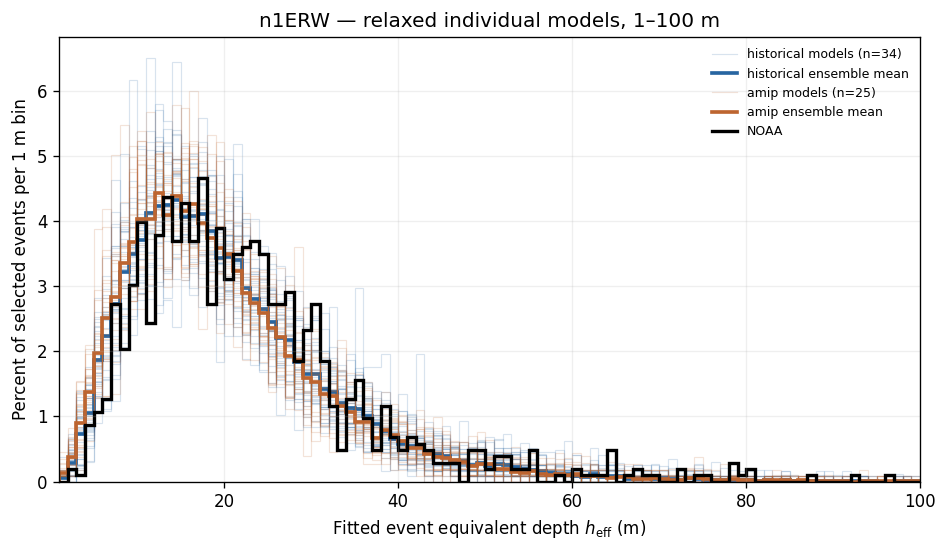

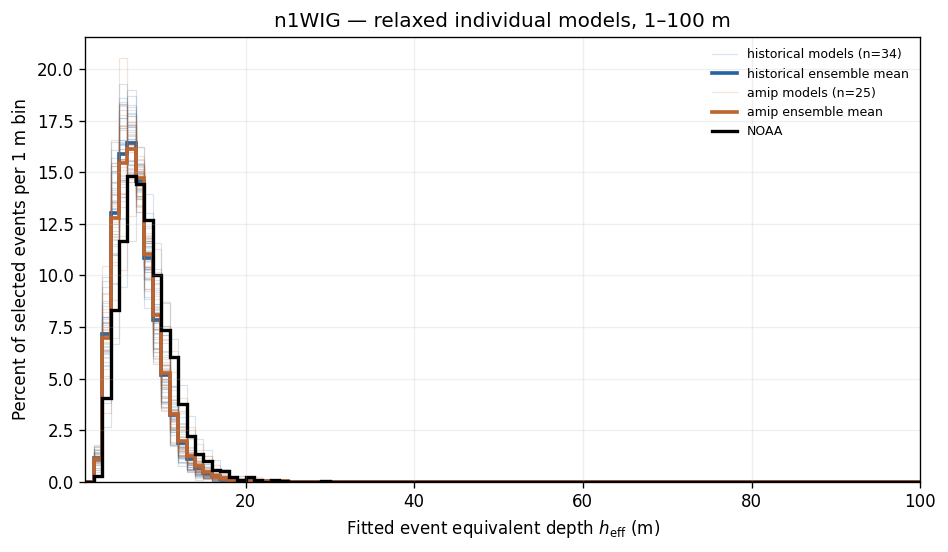

In [6]:
for selection in ("screened", "relaxed"):
    for wave in WAVES:
        fig, ax = plt.subplots(figsize=(8.0, 4.7), dpi=120)
        for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
            rows = model_counts.loc[(model_counts.wave_type == wave)
                                    & (model_counts.selection == selection)
                                    & (model_counts.experiment == experiment)].sort_values(["model", "member"])
            percent = (100 * rows[LINEAR_DETAIL_BINS].to_numpy(dtype=float)
                       / rows.selected_events.to_numpy()[:, None])
            for index, values in enumerate(percent):
                ax.stairs(values, LINEAR_DETAIL_EDGES_M, color=color,
                          linewidth=0.7, alpha=0.18,
                          label=f"{experiment} models (n={len(rows)})" if index == 0 else "_nolegend_")
            ax.stairs(percent.mean(axis=0), LINEAR_DETAIL_EDGES_M, color=color,
                      linewidth=2.2, label=f"{experiment} ensemble mean")
        row = noaa_counts.loc[(noaa_counts.wave_type == wave)
                              & (noaa_counts.selection == selection)].iloc[0]
        noaa_percent = (100 * row[LINEAR_DETAIL_BINS].to_numpy(dtype=float)
                        / row.selected_events)
        ax.stairs(noaa_percent, LINEAR_DETAIL_EDGES_M, color="black",
                  linewidth=2.0, label="NOAA")
        ax.set(xlim=(1, 100), ylim=(0, None),
               xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
               ylabel="Percent of selected events per 1 m bin",
               title=f"{wave} — {selection} individual models, 1–100 m")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=7.5)
        fig.tight_layout()
        display(fig)
        plt.close(fig)


## Event-footprint energy by fitted depth

The y-axis is percent of each record's **total projected OLR anomaly energy per 1 m bin**. It therefore retains differences in both event prevalence and event strength across records. The model bands show between-simulation spread, not uncertainty for an individual model or NOAA. The tabulated `fitted_12_to_50_pct` gives the corresponding sinusoid-explained diagnostic.


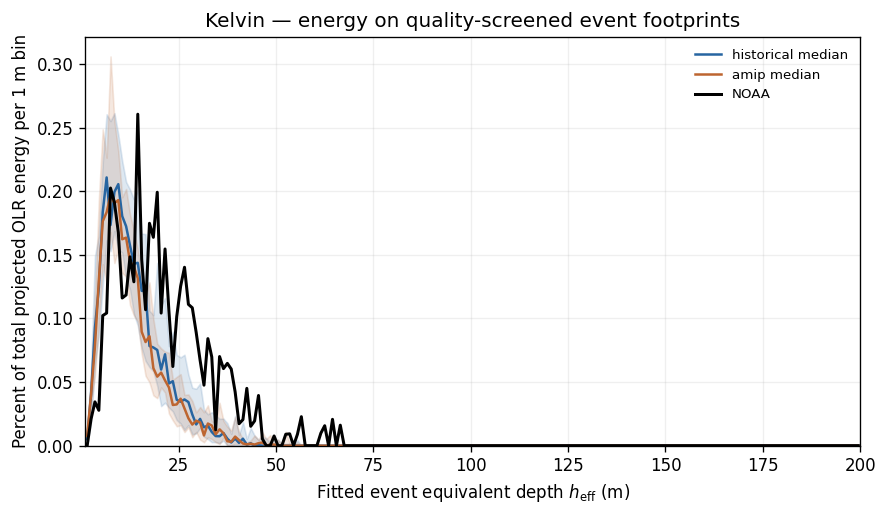

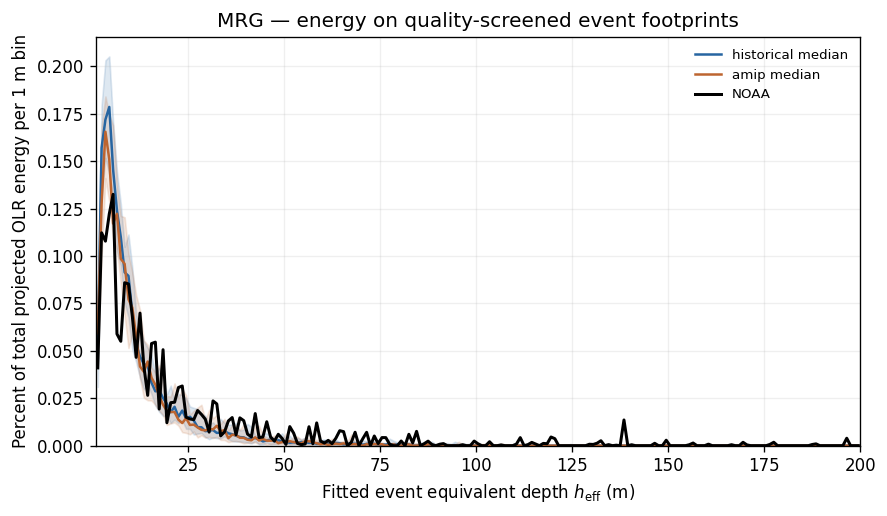

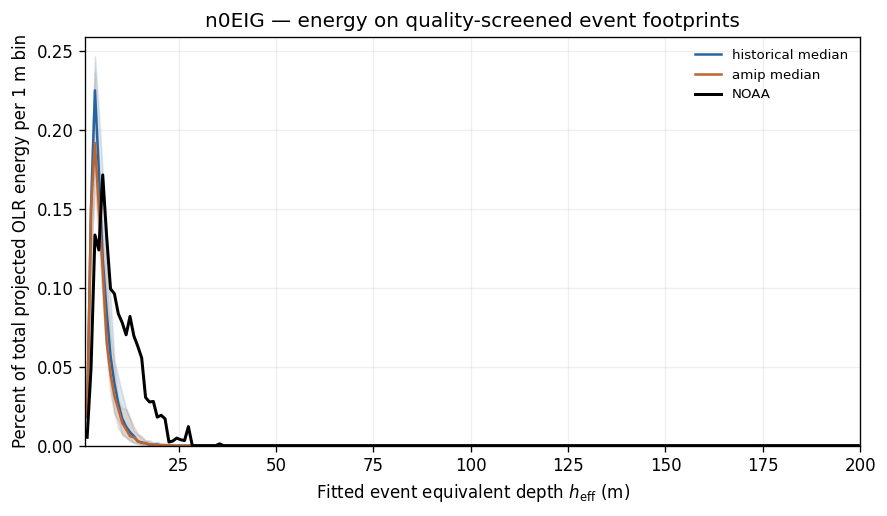

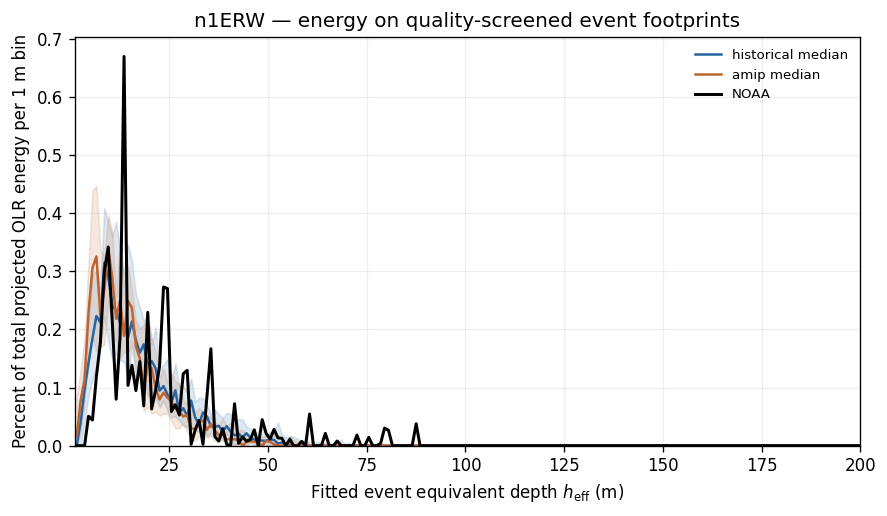

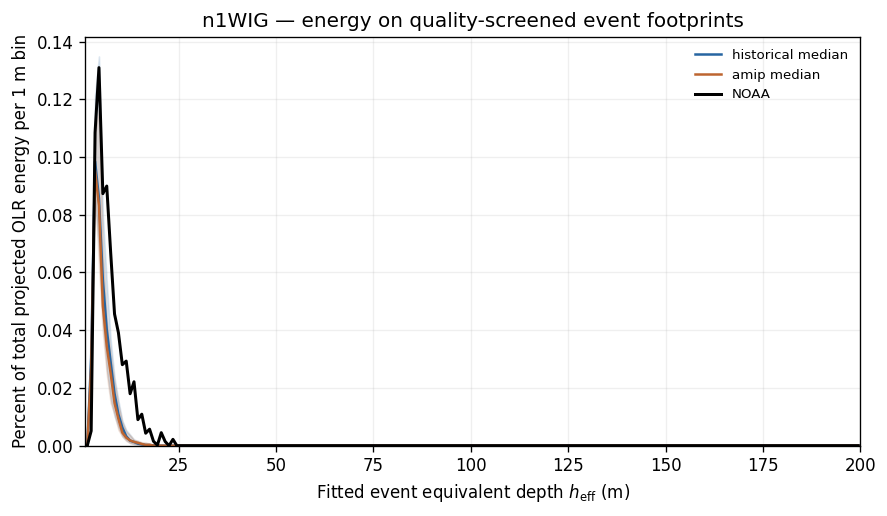

In [7]:
centers = (LINEAR_EDGES_M[:-1] + LINEAR_EDGES_M[1:]) / 2
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
    for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
        rows = model_energy.loc[(model_energy.wave_type == wave)
                                & (model_energy.selection == "screened")
                                & (model_energy.experiment == experiment)]
        fractions = 100 * rows[SUPPORT_BINS].to_numpy() / rows.denominator_energy.to_numpy()[:, None]
        low, median, high = np.quantile(fractions, [0.25, 0.5, 0.75], axis=0)
        ax.plot(centers, median, color=color, label=f"{experiment} median")
        ax.fill_between(centers, low, high, color=color, alpha=0.15)
    row = noaa_energy.loc[(noaa_energy.wave_type == wave)
                          & (noaa_energy.selection == "screened")].iloc[0]
    noaa_fraction = 100 * row[SUPPORT_BINS].to_numpy(dtype=float) / row.denominator_energy
    ax.plot(centers, noaa_fraction, color="black", linewidth=1.8, label="NOAA")
    ax.set(xlim=(1, 200), ylim=(0, None),
           xlabel=r"Fitted event equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Percent of total projected OLR energy per 1 m bin",
           title=f"{wave} — energy on quality-screened event footprints")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Spectral power by apparent depth

This calculation is independent of the event detector and fit-quality screen. Each Fourier cell in the actual filter box is assigned a depth through its wave-family dispersion relation. A spectral excess can coexist with a similar event-fit depth distribution because the latter bins thresholded, fitted components rather than individual Fourier cells. The table above also reports each source's absolute 12–50 m power relative to its own smooth Gaussian spectrum.


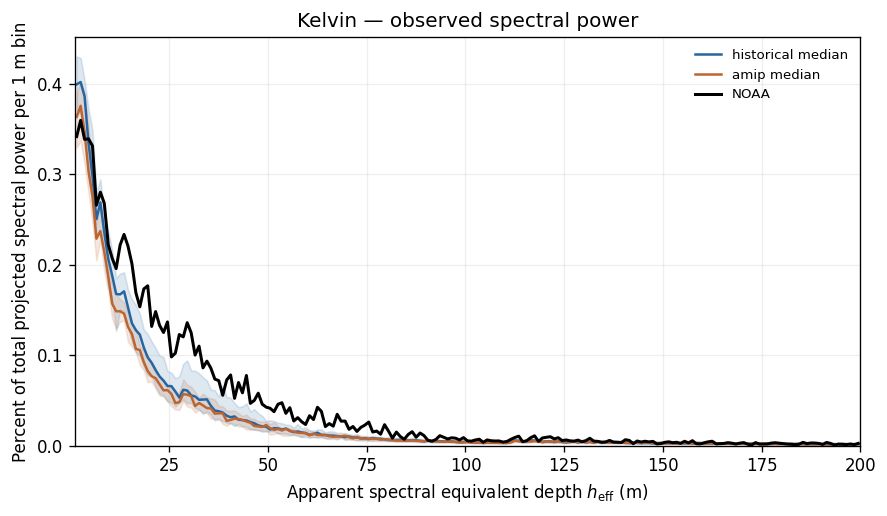

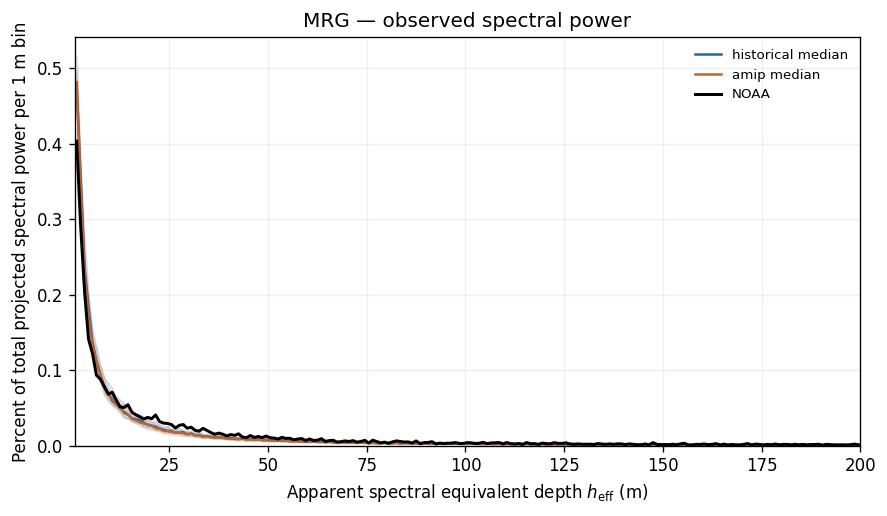

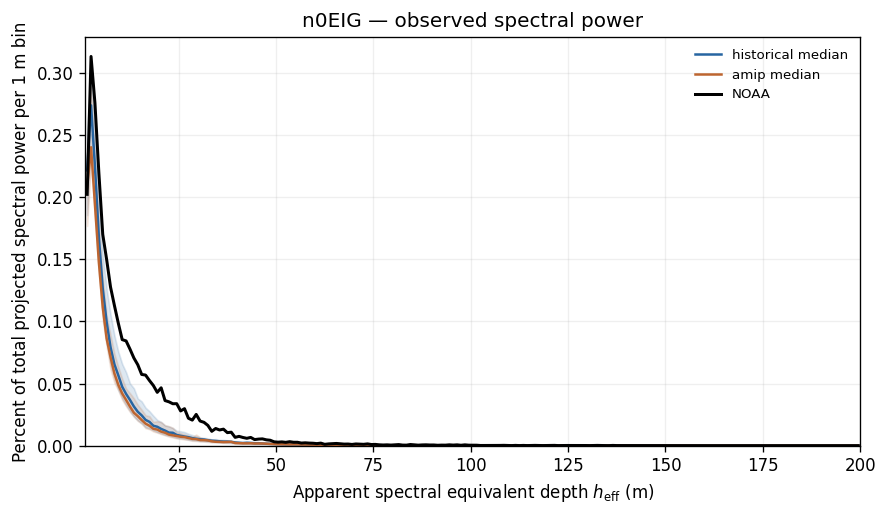

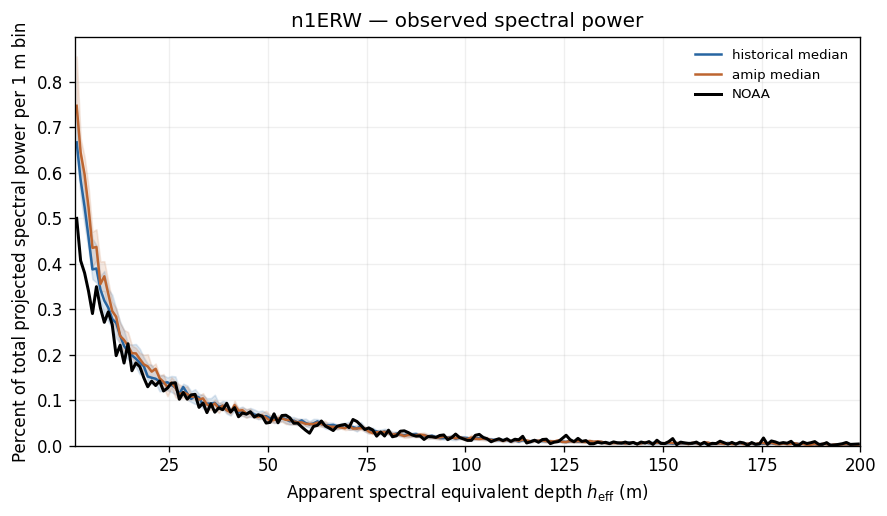

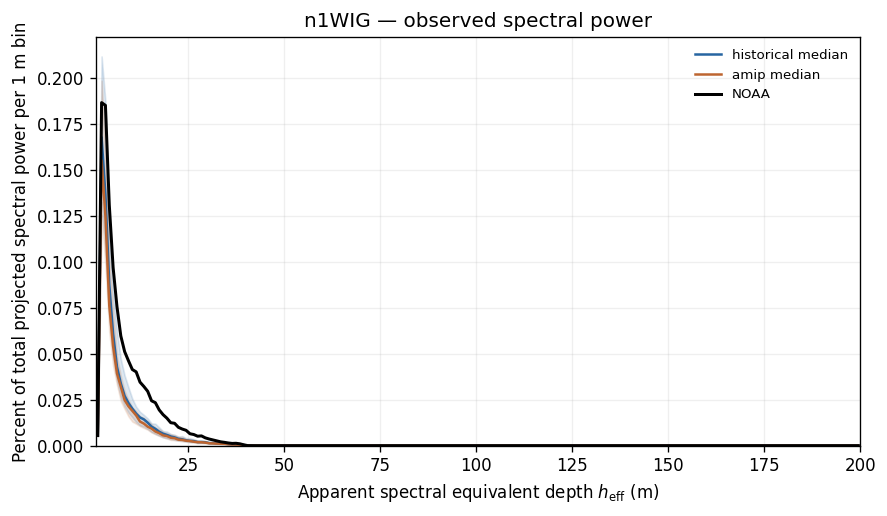

In [8]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), dpi=120)
    for experiment, color in (("historical", "#2765a1"), ("amip", "#bd6530")):
        rows = model_spectral.loc[(model_spectral.wave_type == wave)
                                  & (model_spectral.source == "observed")
                                  & (model_spectral.experiment == experiment)]
        fractions = 100 * rows[POWER_BINS].to_numpy() / rows.denominator_power.to_numpy()[:, None]
        low, median, high = np.quantile(fractions, [0.25, 0.5, 0.75], axis=0)
        ax.plot(centers, median, color=color, label=f"{experiment} median")
        ax.fill_between(centers, low, high, color=color, alpha=0.15)
    row = noaa_spectral.loc[(noaa_spectral.wave_type == wave)
                            & (noaa_spectral.source == "observed")].iloc[0]
    noaa_fraction = 100 * row[POWER_BINS].to_numpy(dtype=float) / row.denominator_power
    ax.plot(centers, noaa_fraction, color="black", linewidth=1.8, label="NOAA")
    ax.set(xlim=(1, 200), ylim=(0, None),
           xlabel=r"Apparent spectral equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Percent of total projected spectral power per 1 m bin",
           title=f"{wave} — observed spectral power")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## Interpretation and limits

For the quality-screened **12–50 m** range, NOAA assigns 70.0% of Kelvin events to this interval, versus a median 45.8% across the 59 model/experiment records. The corresponding event-share comparisons are 23.3% versus 4.4% for EIG and 9.3% versus 2.7% for WIG. NOAA's event-footprint energy in this range is 3.180% of total projected OLR energy for Kelvin, versus Historical/AMIP medians of 1.559/1.441%; 0.441% versus 0.031/0.025% for EIG; and 0.080% versus 0.006/0.006% for WIG. The relaxed valid-depth selection preserves these directional differences. MRG differences are smaller; ER event-footprint energy is broadly similar between NOAA and the model medians.

The independent spectral calculation also puts more NOAA power in this range for Kelvin (4.258% of total projected power versus Historical/AMIP medians 2.485/2.283%) and EIG (0.971% versus 0.345/0.294%). NOAA's 12–50 m spectral power is 1.576 times its smooth Gaussian background for Kelvin and 1.390 for EIG; the model median ratios are about 1.2–1.3 for Kelvin and near 1 for EIG. WIG's NOAA spectral *share* exceeds the model medians, but its observed/background spectral ratio is only 1.014, so that difference alone is not evidence of a distinct WIG spectral peak. ER spectral shares are similar or somewhat higher in the models.

The clearest descriptive model/observation separation here is therefore in **OLR activity mapped or fitted to 12–50 m Kelvin and EIG depths**. These are not direct vertical-mode measurements: different wave amplitudes, propagation parameters, event morphology, and the zero-background-wind inversion can all affect the inferred depths. The 59 records include paired Historical and AMIP runs of some models and only one available member per simulation, so they are not independent draws for a formal significance test. The model bands are between-simulation interquartile ranges; NOAA has one record. Event-footprint energy includes background energy on active pixels, while spectral depth is assigned to Fourier cells. No figures are saved outside this notebook.